# **Powering Palo Alto: Data-Driven Insights for EV Charging Operations**

**42577 Introduction to Business Analytics** · DTU · Group 17

| Name | Student number |
|---|---|
| Georgia Panagopoulou | s263152 |
| Gonçalo Figueira | s263184 |
| Gyorkem Yozgyur | s263126 |
| Teresa Simão | s263065 |

-----------------------------------------

## **1. Data Pre-Processing**

-----------------------------------------

### Table of Contents

* [1.1 Importing the Datasets and Libraries](#1.1)
* [1.2 Preliminary Data Analysis and Arrangements](#1.2)
* [1.3 Exploring Data Distributions](#1.3)
* [1.4 Treating Inconsistencies](#1.4)
* [1.5 Feature Engeneering](#1.5)
* [1.6 Data Visualization](#1.6)
* [1.7 Exporting the Datasets](#1.7)

-----------------------------------------

<a id="1.1"></a>
    
## <font color='#FFFFF'>1.1. Importing the datasets and libraries <font>

This section, as mentioned in the title, is intended for importing the data and necessary libraries.

We import the libraries used throughout the project for data manipulation (pandas, numpy) and visualization (matplotlib, seaborn), suppress warnings and display all columns.

In [281]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

The charging sessions dataset is loaded into a DataFrame; `low_memory=False` avoids mixed-type warnings when reading the file.

In [282]:
df = pd.read_csv("Data/EVChargingStationUsage.csv", low_memory=False)

A first look at the dataset dimensions and its first rows to understand its general structure.

In [283]:
print(df.shape)
df.head()

(259415, 33)


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),Energy (kWh),GHG Savings (kg),Gasoline Savings (gallons),Port Type,Port Number,Plug Type,EVSE ID,Address 1,City,State/Province,Postal Code,Country,Latitude,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,6.249457,2.625,0.784,Level 2,2,J1772,NaN,250 Hamilton Ave,Palo Alto,California,94301,United States,37.444572,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,0.106588,0.045,0.013,Level 2,2,J1772,NaN,250 Hamilton Ave,Palo Alto,California,94301,United States,37.444572,-122.160309,USD,0.0,Customer,4,94301.0,4169,NaN,NaN,NaN
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 8:16,PDT,7/30/2011 12:34,PDT,7/30/2011 12:34,4:17:32,4:17:28,14.951777,6.280,1.876,Level 2,2,J1772,NaN,250 Hamilton Ave,Palo Alto,California,94301,United States,37.444572,-122.160309,USD,0.0,Plug Out at Vehicle,5,94301.0,4169,NaN,NaN,NaN
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 14:51,PDT,7/30/2011 16:55,PDT,7/30/2011 16:55,2:03:24,2:02:58,7.159643,3.007,0.899,Level 2,2,J1772,NaN,250 Hamilton Ave,Palo Alto,California,94301,United States,37.444572,-122.160309,USD,0.0,Customer,6,94302.0,2545,NaN,NaN,NaN
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 18:51,PDT,7/30/2011 20:03,PDT,7/30/2011 20:03,1:11:24,0:43:54,1.957765,0.822,0.246,Level 2,2,J1772,NaN,250 Hamilton Ave,Palo Alto,California,94301,United States,37.444572,-122.160309,USD,0.0,Plug Out at Vehicle,7,94043.0,3765,NaN,NaN,NaN


-----------------------------------------

<a id="1.2"></a>
    
## <font color='#FFFFF'>1.2. Preliminary Data Analysis and Arrangements <font>

In this section we inspect the structure of the dataset: column types, missing values, duplicates, time span and number of users/stations.

`info()` shows the data type and number of non-null values of each column.

In [284]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 259415 entries, 0 to 259414
Data columns (total 33 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Station Name                     259415 non-null  str    
 1   MAC Address                      259415 non-null  str    
 2   Org Name                         259415 non-null  str    
 3   Start Date                       259415 non-null  str    
 4   Start Time Zone                  259415 non-null  str    
 5   End Date                         259415 non-null  str    
 6   End Time Zone                    259415 non-null  str    
 7   Transaction Date (Pacific Time)  259206 non-null  str    
 8   Total Duration (hh:mm:ss)        259415 non-null  str    
 9   Charging Time (hh:mm:ss)         259415 non-null  str    
 10  Energy (kWh)                     259415 non-null  float64
 11  GHG Savings (kg)                 259415 non-null  float64
 12  Gasoline Savi

We compute the number and percentage of missing values per column, keeping only the columns that have any.

In [285]:
missing = pd.DataFrame({
    "Missing": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
})
missing[missing["Missing"] > 0].sort_values("Missing", ascending=False)

,Missing,Missing (%)
County,84665,32.64
EVSE ID,78948,30.43
System S/N,78948,30.43
Model Number,78948,30.43
Driver Postal Code,8402,3.24
User ID,7677,2.96
Currency,1788,0.69
Ended By,248,0.10
Transaction Date (Pacific Time),209,0.08
Port Type,9,0.00


We check for duplicated rows, count unique users, stations and ports, identify the time span of the data and look at the time zones recorded.

In [286]:
print("Duplicated rows:", df.duplicated().sum())
print("Unique User IDs:", df["User ID"].nunique())
print("Unique Station Names:", df["Station Name"].nunique())
print("Unique Port Numbers:", df["Port Number"].nunique())

start_dates = pd.to_datetime(df["Start Date"], errors="coerce")
print("First Start Date:", start_dates.min())
print("Last Start Date:", start_dates.max())

print()
print(df["Start Time Zone"].value_counts())
print()
print(df["End Time Zone"].value_counts())

Duplicated rows: 4
Unique User IDs: 21441
Unique Station Names: 47
Unique Port Numbers: 2
First Start Date: 2011-07-29 20:17:00
Last Start Date: 2020-12-31 18:19:00

Start Time Zone
PDT    166763
PST     92621
UTC        31
Name: count, dtype: int64

End Time Zone
PDT    166791
PST     92623
UTC         1
Name: count, dtype: int64


Summary statistics of the numeric columns, to get a sense of their ranges and spot possible outliers.

In [287]:
df.describe()

,Energy (kWh),GHG Savings (kg),Gasoline Savings (gallons),Port Number,EVSE ID,Postal Code,Latitude,Longitude,Fee,Plug In Event Id,Driver Postal Code,System S/N
count,259415.000000,259415.000000,259415.000000,259415.000000,1.804670e+05,259415.000000,259415.000000,259415.000000,259415.000000,2.594150e+05,251013.000000,1.804670e+05
mean,8.544277,3.588596,1.072306,1.591627,1.462973e+05,94302.315768,37.439565,-122.151264,1.097481,1.188685e+08,94170.308255,1.443790e+11
std,7.185462,3.017894,0.901776,0.491534,2.429677e+05,1.941657,0.009621,0.015382,1.934408,4.057750e+08,4249.837126,2.483280e+10
min,0.010000,0.004000,0.001000,1.000000,3.792000e+03,94301.000000,37.422104,-122.163239,0.000000,1.000000e+00,1013.000000,1.023100e+11
25%,3.784000,1.589000,0.475000,1.000000,4.358300e+04,94301.000000,37.428318,-122.162170,0.000000,1.573000e+03,94087.000000,1.231100e+11
50%,6.868634,2.885000,0.862000,2.000000,1.074270e+05,94301.000000,37.444489,-122.158272,0.000000,3.573000e+03,94304.000000,1.427410e+11
75%,11.458340,4.813000,1.438000,2.000000,1.745590e+05,94303.000000,37.446613,-122.145699,1.640000,6.340000e+03,94804.000000,1.705410e+11
max,97.360000,40.891000,12.219000,2.000000,5.535441e+06,94306.000000,37.449375,-122.112480,84.560000,1.609436e+09,99354.000000,2.002410e+11


Country, State/Province, City and Org Name are constant (Org Name only differs by a trailing space), so they carry no information. EVSE ID, System S/N and Model Number are technical identifiers missing for all sessions until mid-2016, and County is ~33% missing and inconsistent (Palo Alto lies entirely in Santa Clara County), so they are dropped. Currency is kept until section 1.4, because 14 sessions were charged in EUR, MXN or CAD instead of USD.

In [288]:
cols_to_drop = ["EVSE ID", "County", "System S/N", "Model Number",
                "Org Name", "Country", "State/Province", "City"]
df = df.drop(columns=cols_to_drop)
print(df.shape)

(259415, 25)


We look at the categories of the main categorical columns to understand their levels and spot rare or inconsistent values.

In [289]:
for col in ["Port Type", "Plug Type", "Ended By"]:
    print(df[col].value_counts(dropna=False))
    print()

Port Type
Level 2    254727
Level 1      4679
NaN             9
Name: count, dtype: int64

Plug Type
J1772         254734
NEMA 5-20R      4681
Name: count, dtype: int64

Ended By
Plug Out at Vehicle             210721
Customer                         41090
CPS Server                        7065
NaN                                248
Outlet Unreachable                  64
Door Open                           57
Plug Removed While Rebooting        50
Unknown                             32
Final GFCI Tripped                  28
Door                                24
Final 4-strikes GFCI trip           15
Plug Out at Station                  7
Holster Plugin                       7
Station Offline                      3
OCD                                  2
Door Closed                          1
Relay Stuck Closed                   1
Name: count, dtype: int64



Columns are renamed to short snake_case names to make the code easier to write and read in the following sections.

In [290]:
df = df.rename(columns={
    "Station Name": "station", "MAC Address": "mac_address",
    "Start Date": "start", "Start Time Zone": "start_tz",
    "End Date": "end", "End Time Zone": "end_tz",
    "Transaction Date (Pacific Time)": "transaction_date",
    "Total Duration (hh:mm:ss)": "total_duration", "Charging Time (hh:mm:ss)": "charging_time",
    "Energy (kWh)": "energy_kwh", "GHG Savings (kg)": "ghg_kg", "Gasoline Savings (gallons)": "gasoline_gal",
    "Port Type": "port_type", "Port Number": "port_number", "Plug Type": "plug_type",
    "Address 1": "address", "Postal Code": "postal_code",
    "Latitude": "lat", "Longitude": "lon", "Fee": "fee", "Currency": "currency", "Ended By": "ended_by",
    "Plug In Event Id": "event_id", "Driver Postal Code": "driver_postal_code", "User ID": "user_id"
})
df.columns

Index(['station', 'mac_address', 'start', 'start_tz', 'end', 'end_tz',
       'transaction_date', 'total_duration', 'charging_time', 'energy_kwh',
       'ghg_kg', 'gasoline_gal', 'port_type', 'port_number', 'plug_type',
       'address', 'postal_code', 'lat', 'lon', 'currency', 'fee', 'ended_by',
       'event_id', 'driver_postal_code', 'user_id'],
      dtype='str')

Dates are converted to datetime and durations to timedelta (also expressed in hours), while repetitive text columns become categories to save memory. 40 end dates stored in Excel numeric format fail to parse; end is recomputed in 1.4. Postal codes and event IDs are stored as text, since they are codes, not quantities.

In [291]:
for col in ["start", "end", "transaction_date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

for col in ["total_duration", "charging_time"]:
    df[col] = pd.to_timedelta(df[col], errors="coerce")

df["total_hours"] = df["total_duration"].dt.total_seconds() / 3600
df["charging_hours"] = df["charging_time"].dt.total_seconds() / 3600

for col in ["station", "port_type", "plug_type", "ended_by"]:
    df[col] = df[col].astype("category")

df["driver_postal_code"] = df["driver_postal_code"].astype("Int64").astype("string")
for col in ["postal_code", "event_id"]:
    df[col] = df[col].astype("string")

print(df[["start", "end", "transaction_date", "total_duration", "charging_time"]].isna().sum())
df.dtypes

start                 0
end                  40
transaction_date    249
total_duration        0
charging_time         0
dtype: int64


station                      category
mac_address                       str
start                  datetime64[us]
start_tz                          str
end                    datetime64[us]
end_tz                            str
transaction_date       datetime64[us]
total_duration        timedelta64[us]
charging_time         timedelta64[us]
energy_kwh                    float64
ghg_kg                        float64
gasoline_gal                  float64
port_type                    category
port_number                     int64
plug_type                    category
address                           str
postal_code                     int64
lat                           float64
lon                           float64
currency                          str
fee                           float64
ended_by                     category
event_id                        int64
driver_postal_code            float64
user_id                           str
total_hours                   float64
charging_hou

The number of sessions per year shows how the data volume evolves over time and which periods are well represented.

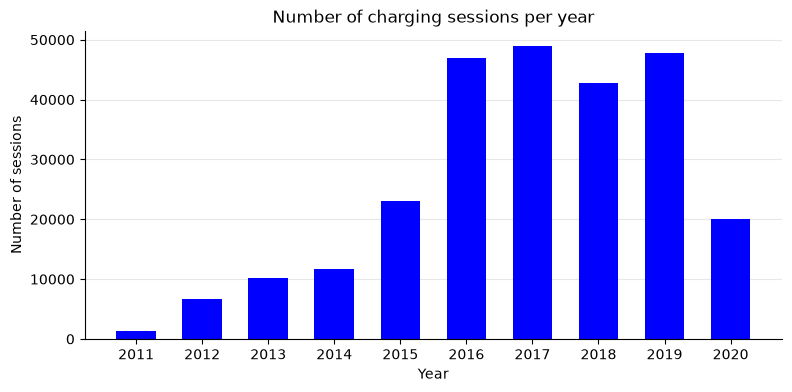

In [292]:
sessions_per_year = df["start"].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(sessions_per_year.index, sessions_per_year.values, color="blue", width=0.6)
ax.set_title("Number of charging sessions per year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of sessions")
ax.set_xticks(sessions_per_year.index)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

For each station we count its sessions and find its first and last session, to identify stations with short activity periods.

In [293]:
station_activity = (df.groupby("station", observed=True)["start"]
                    .agg(sessions="count", first_session="min", last_session="max")
                    .sort_values("sessions", ascending=False))
station_activity

,sessions,first_session,last_session
station,,,
PALO ALTO CA / HAMILTON #2,23721,2011-08-02 12:26:00,2020-11-04 04:54:00
PALO ALTO CA / HAMILTON #1,14888,2011-07-29 20:17:00,2020-11-03 18:03:00
PALO ALTO CA / WEBSTER #1,14432,2015-07-29 13:59:00,2020-12-31 17:49:00
PALO ALTO CA / BRYANT #2,14389,2011-10-10 15:23:00,2020-07-01 13:26:00
PALO ALTO CA / HIGH #4,13898,2011-09-02 20:42:00,2020-12-06 16:36:00
PALO ALTO CA / BRYANT #1,13436,2011-10-13 12:49:00,2020-08-30 13:22:00
PALO ALTO CA / WEBSTER #2,12669,2015-07-29 16:53:00,2020-12-30 17:57:00
PALO ALTO CA / CAMBRIDGE #1,11163,2016-01-14 11:19:00,2020-12-31 06:50:00
PALO ALTO CA / HIGH #1,10756,2015-07-29 15:51:00,2020-12-31 09:37:00


**Summary of 1.2**

- 259,415 sessions (Jul 2011 – Dec 2020), 21,441 users, 47 stations, at most 2 ports per station.
- Dates and durations were converted from text; 40 end dates in Excel numeric format failed to parse (fixed in 1.4).
- Eight constant or uninformative columns were dropped; currency is kept for 1.4 (14 non-USD sessions).
- User ID is missing in ~3% of sessions, which limits clustering but not forecasting.
- 4 duplicates and 32 sessions with UTC timestamps are handled in 1.4.
- Volume is low before 2015, stable at ~43–49k sessions/year in 2016–2019, and drops by more than half in 2020 (COVID-19).
- 14 SHERMAN stations and “BRYANT # 1” only appear in late 2020.

-----------------------------------------

<a id="1.3"></a>
    
## <font color='#FFFFF'>1.3. Exploring Data Distributions <font>

Before cleaning, we look at the distributions of the key numeric variables to detect outliers and impossible values.

We create `idle_hours`, the time a vehicle stays plugged in without charging, which indicates potential hoarding of the charging port.

In [294]:
df["idle_hours"] = df["total_hours"] - df["charging_hours"]
df[["total_hours", "charging_hours", "idle_hours"]].head()

,total_hours,charging_hours,idle_hours
0,3.058889,1.900833,1.158056
1,0.035000,0.031667,0.003333
2,4.292222,4.291111,0.001111
3,2.056667,2.049444,0.007222
4,1.190000,0.731667,0.458333


Histograms of energy and session times show their shape; values are clipped at the 99th percentile so that extreme outliers do not hide the bulk of the data. Idle time is also cut at 0 and shown on a log scale, so the hoarding tail is visible.

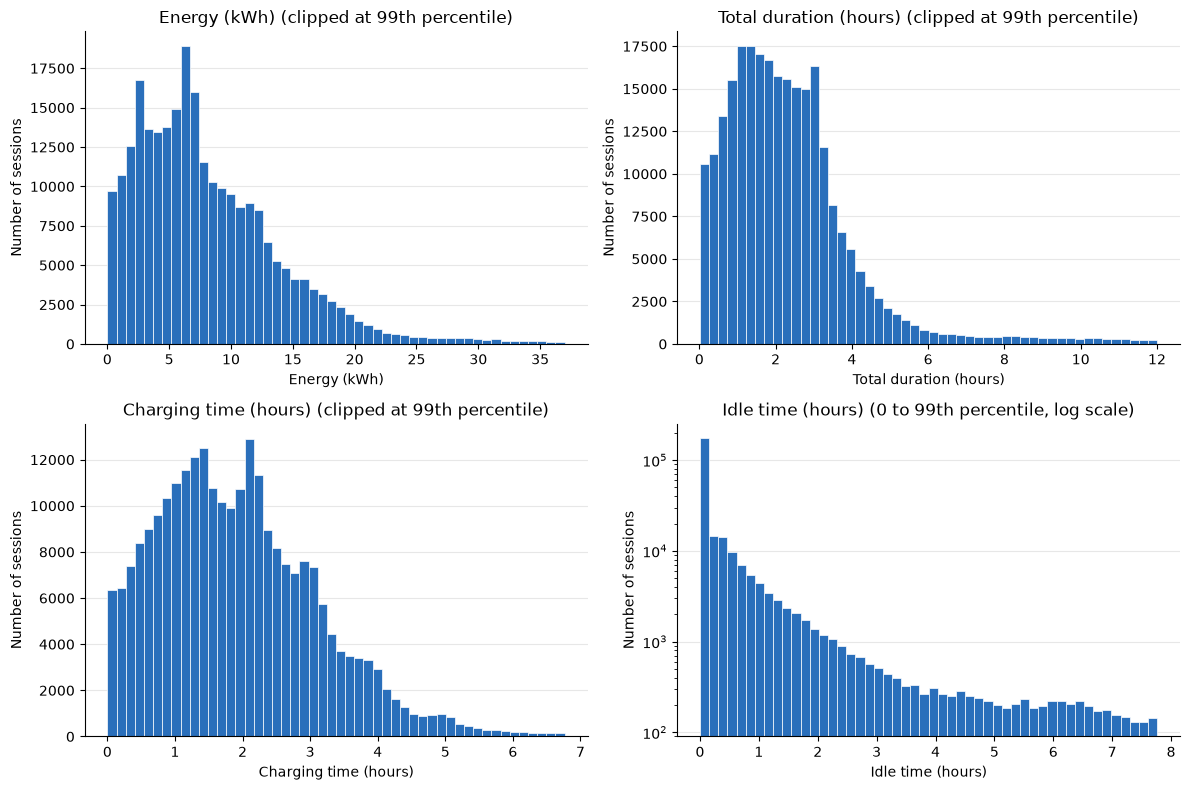

In [295]:
cols = {"energy_kwh": "Energy (kWh)", "total_hours": "Total duration (hours)",
        "charging_hours": "Charging time (hours)", "idle_hours": "Idle time (hours)"}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, label) in zip(axes.flat, cols.items()):
    p99 = df[col].quantile(0.99)
    low = 0 if col == "idle_hours" else df[col].min()
    data = df.loc[(df[col] >= low) & (df[col] <= p99), col]
    ax.hist(data, bins=50, color="#2a6fbb", edgecolor="white", linewidth=0.5)
    if col == "idle_hours":
        ax.set_yscale("log")
        ax.set_title(f"{label} (0 to 99th percentile, log scale)")
    else:
        ax.set_title(f"{label} (clipped at 99th percentile)")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of sessions")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

We look at the fees of paid sessions (clipped at the 99th percentile) and at the share of free sessions.

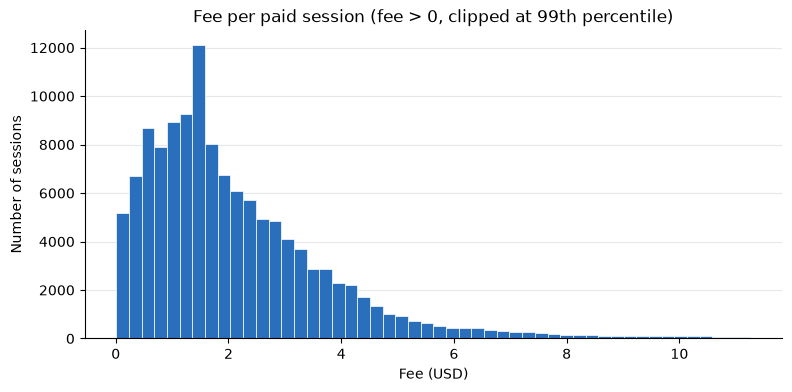

Free sessions (fee == 0): 51.5%
Median fee of paid sessions: 1.69 USD


In [296]:
paid = df.loc[df["fee"] > 0, "fee"]
p99 = paid.quantile(0.99)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(paid[paid <= p99], bins=50, color="#2a6fbb", edgecolor="white", linewidth=0.5)
ax.set_title("Fee per paid session (fee > 0, clipped at 99th percentile)")
ax.set_xlabel("Fee (USD)")
ax.set_ylabel("Number of sessions")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(f"Free sessions (fee == 0): {(df['fee'] == 0).mean() * 100:.1f}%")
print(f"Median fee of paid sessions: {paid.median():.2f} USD")

Boxplots show that all variables are strongly right-skewed. Most points beyond the whiskers are genuine long sessions, not errors, so cleaning in 1.4 uses physical rules (e.g. > 24 h, negative idle time) instead of the IQR rule.

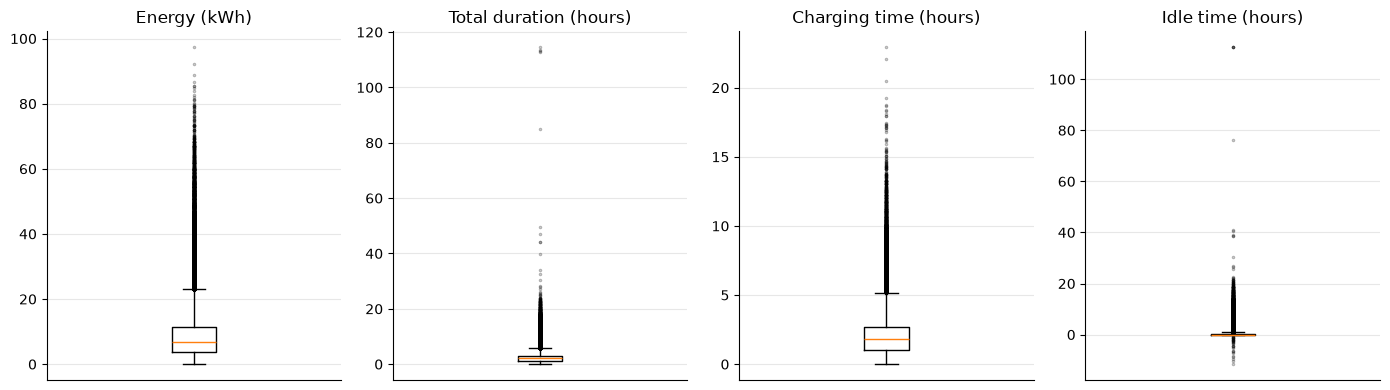

In [297]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (col, label) in zip(axes, cols.items()):
    ax.boxplot(df[col].dropna(), flierprops={"marker": ".", "markersize": 3, "alpha": 0.3})
    ax.set_title(label)
    ax.set_xticks([])
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The upper edge of the cloud (≈ 6.6 kWh per hour) reflects the maximum power of Level 2 chargers; points far below it are long, low-energy sessions, i.e. potential hoarding. A few points above the edge imply an impossible charging power and are removed in 1.4.

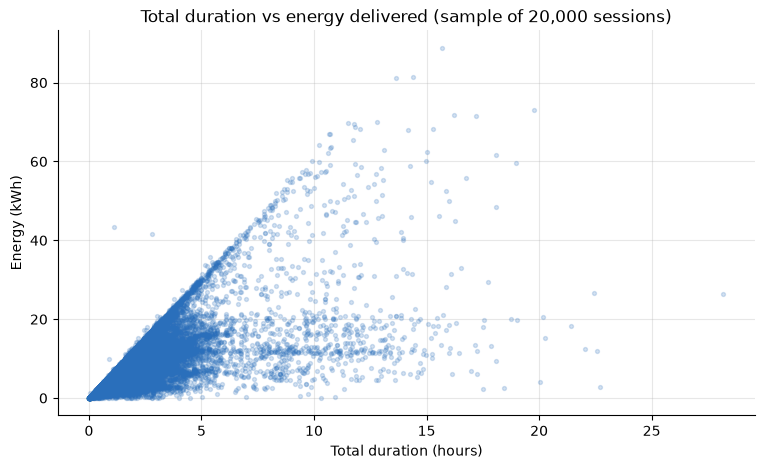

In [298]:
sample = df.sample(20000, random_state=42)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(sample["total_hours"], sample["energy_kwh"], s=8, alpha=0.2, color="#2a6fbb")
ax.set_title("Total duration vs energy delivered (sample of 20,000 sessions)")
ax.set_xlabel("Total duration (hours)")
ax.set_ylabel("Energy (kWh)")
ax.grid(alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

We count suspicious or invalid sessions according to several rules, to decide which ones to clean or remove in section 1.4.

In [299]:
checks = {
    "Total duration < 2 min": df["total_hours"] < 2 / 60,
    "Total duration > 24 h": df["total_hours"] > 24,
    "Charging time > total duration (negative idle)": df["charging_hours"] > df["total_hours"],
    "Avg power > 20 kW (impossible for Level 2)": df["energy_kwh"] / df["charging_hours"].where(df["charging_hours"] > 0) > 20,
    "Energy < 0.1 kWh": df["energy_kwh"] < 0.1,
    "Negative fee": df["fee"] < 0,
    "UTC time zone": (df["start_tz"] == "UTC") | (df["end_tz"] == "UTC"),
    "Currency not USD": df["currency"].notna() & (df["currency"] != "USD"),
    "Currency missing": df["currency"].isna(),
    "User ID missing": df["user_id"].isna(),
    "Duplicated rows": df.duplicated(),
}

suspicious = pd.DataFrame({
    "Sessions": {k: v.sum() for k, v in checks.items()},
    "%": {k: round(v.mean() * 100, 2) for k, v in checks.items()},
})
print(suspicious)

                                                Sessions     %
Total duration < 2 min                              1272  0.49
Total duration > 24 h                                 22  0.01
Charging time > total duration (negative idle)        45  0.02
Avg power > 20 kW (impossible for Level 2)            10  0.00
Energy < 0.1 kWh                                    1831  0.71
Negative fee                                           0  0.00
UTC time zone                                         32  0.01
Currency not USD                                      14  0.01
Currency missing                                    1788  0.69
User ID missing                                     7677  2.96
Duplicated rows                                        4  0.00


**Summary of 1.3**
- All time and energy variables are right-skewed: a typical session lasts ~2.1 h, charges for ~1.8 h and delivers ~6.9 kWh, but durations reach 115 h.
- Idle time is usually near zero (median < 1 min), yet 12% of sessions stay plugged in for over 1 h without charging, a sign of port hoarding.
- Energy is more related to charging time (r = 0.87) than to total duration (r = 0.64), since many cars stay plugged in after charging.
- Charging was free until mid-2017 and ~99% of sessions are paid since 2018 (median fee 1.69 USD), so the 51.5% share of free sessions reflects a pricing change.
- About 0.8% of sessions break at least one physical validity rule, mostly sessions under 2 minutes or below 0.1 kWh.

-----------------------------------------

<a id="1.4"></a>
    
## <font color='#FFFFF'>1.4. Treating Inconsistencies <font>

Based on the checks of 1.2 and 1.3, we now correct or remove inconsistent sessions. Every step is recorded in a log to keep track of how much data is lost.

In [300]:
n_initial = len(df)
cleaning_log = []

def log_step(step, n_before):
    cleaning_log.append((step, n_before - len(df), len(df)))
    print(f"{step}: {n_before - len(df)} rows removed, {len(df)} remaining")

Exact duplicated rows represent the same session recorded twice, so they are dropped to avoid counting it twice.

In [301]:
n_before = len(df)
df = df.drop_duplicates()
log_step("Duplicates", n_before)

Duplicates: 4 rows removed, 259411 remaining


Some start and end times were recorded in UTC instead of Pacific time. We convert them to local time (America/Los_Angeles) so that all timestamps are comparable. The time zone labels are updated so the conversion cannot be applied twice.

In [302]:
utc_start = df["start_tz"] == "UTC"
utc_end = df["end_tz"] == "UTC"

df.loc[utc_start, "start"] = (df.loc[utc_start, "start"]
                              .dt.tz_localize("UTC").dt.tz_convert("America/Los_Angeles").dt.tz_localize(None))
df.loc[utc_end, "end"] = (df.loc[utc_end, "end"]
                          .dt.tz_localize("UTC").dt.tz_convert("America/Los_Angeles").dt.tz_localize(None))

print("Start times converted:", utc_start.sum())
print("End times converted:", utc_end.sum())
df.loc[utc_start, "start_tz"] = "Pacific (converted)"
df.loc[utc_end, "end_tz"] = "Pacific (converted)"
log_step("Time zones (UTC to Pacific)", len(df))

Start times converted: 31
End times converted: 1
Time zones (UTC to Pacific): 0 rows removed, 259411 remaining


Sessions under 2 minutes are likely connection failures, sessions over 24 hours are unrealistic or faulty, and a charging time longer than the total duration is physically impossible, so all are removed.

In [303]:
n_before = len(df)
invalid_duration = ((df["total_hours"] < 2 / 60) |
                    (df["total_hours"] > 24) |
                    (df["charging_hours"] > df["total_hours"]))
df = df[~invalid_duration]
log_step("Invalid durations", n_before)

Invalid durations: 1338 rows removed, 258073 remaining


Sessions delivering less than 0.1 kWh involve no real charging, so they are removed.

In [304]:
n_before = len(df)
df = df[df["energy_kwh"] >= 0.1]
log_step("Near-empty sessions (< 0.1 kWh)", n_before)

Near-empty sessions (< 0.1 kWh): 768 rows removed, 257305 remaining

An average power above 20 kW is impossible for Level 2 chargers (max ≈ 6.6 kW), so these sessions are recording errors and are removed.

In [305]:
n_before = len(df)
avg_power = df["energy_kwh"] / df["charging_hours"].where(df["charging_hours"] > 0)
df = df[~(avg_power > 20)]
log_step("Implausible power (> 20 kW)", n_before)

Implausible power (> 20 kW): 10 rows removed, 257295 remaining


Sessions charged in a currency other than USD are inconsistent for US stations and are removed. Missing currencies are assumed to be USD, so the column becomes constant and is dropped.

In [306]:
n_before = len(df)
df = df[df["currency"].isna() | (df["currency"] == "USD")]
df = df.drop(columns="currency")
log_step("Non-USD currency", n_before)

Non-USD currency: 13 rows removed, 257282 remaining


Station names are stripped of extra whitespace to avoid duplicate categories.

In [307]:
df["station"] = df["station"].astype(str).str.strip().astype("category")
log_step("Station names (whitespace stripped)", len(df))

Station names (whitespace stripped): 0 rows removed, 257282 remaining


Some end dates are missing or stored in Excel format, and others disagree with the recorded duration. Since `total_duration` comes from the charger, we recompute every end as start + total_duration.

In [308]:
new_end = df["start"] + df["total_duration"]
print("End values missing before:", df["end"].isna().sum())
print("End values changed by > 1 min:", ((new_end - df["end"]).abs() > pd.Timedelta(minutes=1)).sum())
df["end"] = new_end
log_step("End recomputed (start + duration)", len(df))

End values missing before: 40
End values changed by > 1 min: 462
End recomputed (start + duration): 0 rows removed, 257282 remaining


Two cars cannot use the same port at the same time, so sessions starting more than 1 minute before the previous session on the same port has ended are removed, as they would distort occupancy. The 1-minute tolerance absorbs rounding, since start times have no seconds.

In [309]:
n_before = len(df)
df = df.sort_values(["station", "port_number", "start"])
prev_end = df.groupby(["station", "port_number"], observed=True)["end"].shift()
df = df[~(df["start"] < prev_end - pd.Timedelta(minutes=1))].sort_index()
log_step("Overlapping sessions on the same port", n_before)

Overlapping sessions on the same port: 72 rows removed, 257210 remaining


We keep only sessions before March 2020, since demand dropped sharply with COVID-19 and is not representative. This also removes the Sherman stations, which only appear in December 2020.

In [310]:
n_before = len(df)
df = df[df["start"] < "2020-03-01"]
df["station"] = df["station"].cat.remove_unused_categories()
print("Stations remaining:", df["station"].nunique())
print("Date range:", df["start"].min(), "to", df["start"].max())
log_step("Study period (before March 2020)", n_before)

Stations remaining: 33
Date range: 2011-07-29 20:17:00 to 2020-02-29 21:47:00
Study period (before March 2020): 11487 rows removed, 245723 remaining


Sessions without a User ID are kept, as they are still valid for station-level forecasting; they will only be excluded in the clustering task.

In [311]:
print(f"Sessions without user_id: {df['user_id'].isna().sum()} ({df['user_id'].isna().mean() * 100:.2f}%)")

Sessions without user_id: 7153 (2.91%)


The cleaning log summarises how many rows each step removed and how much of the original data remains.

In [312]:
log_df = pd.DataFrame(cleaning_log, columns=["Step", "Rows removed", "Rows remaining"])
log_df["% of original"] = (log_df["Rows remaining"] / n_initial * 100).round(2)
print(log_df.to_string(index=False))
print("\nFinal shape:", df.shape)

                                 Step  Rows removed  Rows remaining  % of original
                           Duplicates             4          259411         100.00
          Time zones (UTC to Pacific)             0          259411         100.00
                    Invalid durations          1338          258073          99.48
      Near-empty sessions (< 0.1 kWh)           768          257305          99.19
          Implausible power (> 20 kW)            10          257295          99.18
                     Non-USD currency            13          257282          99.18
  Station names (whitespace stripped)             0          257282          99.18
    End recomputed (start + duration)             0          257282          99.18
Overlapping sessions on the same port            72          257210          99.15
     Study period (before March 2020)         11487          245723          94.72

Final shape: (245723, 27)


First rows of the cleaned dataset.

In [313]:
df.head()

,station,mac_address,start,start_tz,end,end_tz,transaction_date,total_duration,charging_time,energy_kwh,ghg_kg,gasoline_gal,port_type,port_number,plug_type,address,postal_code,lat,lon,fee,ended_by,event_id,driver_postal_code,user_id,total_hours,charging_hours,idle_hours
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,2011-07-29 20:17:00,PDT,2011-07-29 23:20:32,PDT,2011-07-29 23:20:00,0 days 03:03:32,0 days 01:54:03,6.249457,2.625,0.784,Level 2,2,J1772,250 Hamilton Ave,94301,37.444572,-122.160309,0.0,Plug Out at Vehicle,3,95124.0,3284,3.058889,1.900833,1.158056
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,2011-07-30 00:00:00,PDT,2011-07-30 00:02:06,PDT,2011-07-30 00:02:00,0 days 00:02:06,0 days 00:01:54,0.106588,0.045,0.013,Level 2,2,J1772,250 Hamilton Ave,94301,37.444572,-122.160309,0.0,Customer,4,94301.0,4169,0.035000,0.031667,0.003333
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,2011-07-30 08:16:00,PDT,2011-07-30 12:33:32,PDT,2011-07-30 12:34:00,0 days 04:17:32,0 days 04:17:28,14.951777,6.280,1.876,Level 2,2,J1772,250 Hamilton Ave,94301,37.444572,-122.160309,0.0,Plug Out at Vehicle,5,94301.0,4169,4.292222,4.291111,0.001111
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,2011-07-30 14:51:00,PDT,2011-07-30 16:54:24,PDT,2011-07-30 16:55:00,0 days 02:03:24,0 days 02:02:58,7.159643,3.007,0.899,Level 2,2,J1772,250 Hamilton Ave,94301,37.444572,-122.160309,0.0,Customer,6,94302.0,2545,2.056667,2.049444,0.007222
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,2011-07-30 18:51:00,PDT,2011-07-30 20:02:24,PDT,2011-07-30 20:03:00,0 days 01:11:24,0 days 00:43:54,1.957765,0.822,0.246,Level 2,2,J1772,250 Hamilton Ave,94301,37.444572,-122.160309,0.0,Plug Out at Vehicle,7,94043.0,3765,1.190000,0.731667,0.458333


**Summary of 1.4**

- In total, 13,692 sessions (5.28%) were removed, leaving 245,723 sessions and 33 stations.
- Data-quality issues explain only 2,205 removals (0.85%), mainly invalid durations (1,338) and near-empty sessions (768), plus 72 overlapping sessions, 13 non-USD, 10 with impossible power and 4 duplicates.
- End times were recomputed as start + duration, filling 40 missing values and correcting 462 inconsistent ones.
- The study period is Jul 2011 – Feb 2020 (11,487 sessions removed), since COVID-19 made 2020 demand unrepresentative; BRYANT # 1 and the SHERMAN stations only appear later.
- Assumptions: missing currencies are USD, UTC times were converted to Pacific time, and high fees (up to ~80 USD) are kept as they likely reflect long-stay fees.
- Sessions without User ID (2.91%) are kept for forecasting but excluded from clustering.

-----------------------------------------

<a id="1.7"></a>
    
## <font color='#FFFFF'>1.7. Exporting the Datasets <font>

The cleaned dataset is saved as a pickle file, which preserves data types (datetimes, categories), so the following sections can load it directly.

In [314]:
df.to_pickle("Data/ev_clean.pkl")
print("Saved:", df.shape)

Saved: (245723, 27)


To load it: `df = pd.read_pickle('Data/ev_clean.pkl')`. Note: sessions without user_id must be excluded for user clustering.